In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset, Sampler

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import zscore
import os, math, random

# load data

In [2]:
#mne setup
import openneuro
import os
import mne
from mne.datasets import sample
from mne_bids import (
    BIDSPath,
    find_matching_paths,
    get_entity_vals,
    make_report,
    print_dir_tree,
    read_raw_bids
)

In [5]:
os.getcwd()

'c:\\Users\\BrockRouser-US\\Desktop\\projects\\eeg-deeplearning'

In [8]:
dataset = "ds007169"
if not os.path.exists(os.path.join(os.getcwd(),'ds007169')):
    for i in range(1,21):
        subject = f"00{i}"
        if len(subject)==4:
            subject=subject[1:]
        if subject in ['013', '017']: continue #bad ids
        
        # Create a BIDS root directory in the MNE dataset folder
        bids_root = sample.data_path(download=False).parent / dataset
        bids_root=os.path.join(os.getcwd(),bids_root)
        bids_root.mkdir(parents=True, exist_ok=True)
        openneuro.download(dataset=dataset, target_dir=bids_root, include=[f"sub-{subject}"])
    

In [9]:
def load_subject(subject,
                 session = None,
                task = "nback",
                suffix = "eeg", #has ecg built in
                bids_root='ds007169'):
    bids_root=os.path.join(os.getcwd(),bids_root)
    subject = f"00{subject}"
    if len(subject)==4:subject=subject[1:]
    if subject in ['013', '017']: return None
    bids_path = BIDSPath(root=bids_root, session=session, datatype='eeg')
    bids_path = bids_path.update(subject=subject, task=task, suffix=suffix)
    raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
    return raw

def loadBids()->list:   
    data=[]
    for i in range(1,21):
        raw=load_subject(i)
        if raw is not None: data.append(raw)
    return data

In [10]:
def filter_raw(
    raw,
    eeg_band=(1.0, 40.0),
    ecg_band=(0.5, 40.0),
    line_freq=50.0,
    copy=True,
    verbose="WARNING",
):
    """Bandpass + notch filter EEG and ECG channels of an mne.io.Raw object.

    Parameters
    ----------
    raw : mne.io.BaseRaw
        Raw recording. Data is loaded into memory if it is not already.
    eeg_band, ecg_band : tuple of (l_freq, h_freq)
        Bandpass edges in Hz for EEG and ECG channels respectively.
    line_freq : float
        Mains frequency. 50 Hz for Europe.
    copy : bool
        If True, the input is left untouched and a filtered copy is returned.

    Returns
    -------
    raw : mne.io.BaseRaw
        Filtered data. Channels other than EEG/ECG are left unfiltered.
    """
    if copy:
        raw = raw.copy()
    raw.load_data()

    nyq = raw.info["sfreq"] / 2.0

    # Notch at the line frequency and its harmonics, below Nyquist only
    notch_freqs = [f for f in np.arange(line_freq, nyq, line_freq) if f < nyq]

    groups = {
        "eeg": (dict(eeg=True, ecg=False), eeg_band),
        "ecg": (dict(eeg=False, ecg=True), ecg_band),
    }

    for name, (pick_kwargs, (l_freq, h_freq)) in groups.items():
        picks = mne.pick_types(raw.info, exclude=[], **pick_kwargs)
        if len(picks) == 0:
            continue

        if len(notch_freqs):
            raw.notch_filter(freqs=notch_freqs, picks=picks, verbose=verbose)

        raw.filter(
            l_freq=l_freq,
            h_freq=min(h_freq, nyq - 1.0) if h_freq is not None else None,
            picks=picks,
            method="fir",
            phase="zero",
            fir_design="firwin",
            verbose=verbose,
        )

    return raw

C:\Users\BrockRouser-US\AppData\Local\Temp\ipykernel_32876\2151563219.py:12: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
C:\Users\BrockRouser-US\AppData\Local\Temp\ipykernel_32876\2151563219.py:12: RuntimeWarning: Unable to map the following column(s) to MNE:
handedness: R
analysis_included: true
data_quality_overall: pass
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})


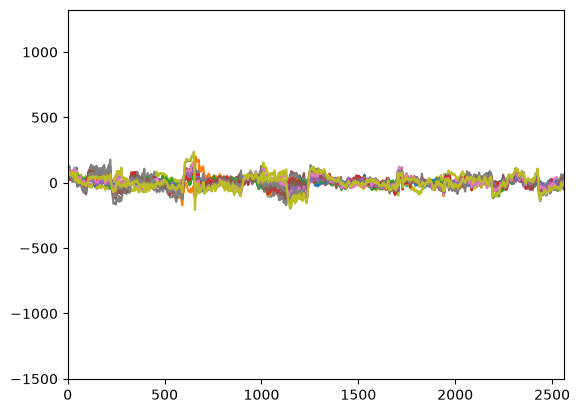

In [11]:
session=load_subject(1)
session=filter_raw(session)
plt.figure()
plt.plot(session.get_data(picks='eeg').T)
plt.xlim([0,256*10])
plt.show()

In [15]:
# save_processed.py
freqs=np.arange(0.1,60,0.5)
n_cycles=freqs/2
for i in range(1,21):
    session=load_subject(i) #returns mne raw object
    if session is None: continue
    session._data*=1e-6 #scale to correct units
    session=filter_raw(session)
    
    raw=zscore(session.get_data(picks=['eeg','ecg']),axis=1)
    raw=torch.tensor(raw)
    
    tfr=session.compute_tfr(method='morlet',freqs=freqs,n_cycles=n_cycles,picks=['eeg','ecg'], verbose=False, decim=4).get_data(picks=['eeg','ecg']) #shape [channel, freq, time]
    tfr=np.log(tfr+ 1e-30) #log transform to better capture high frequency content and avoid log 0
    tfr = zscore(tfr, axis=2)
    tfr=torch.tensor(tfr) #note that temporal dimension varies from raw due to decim factor. When we slice randomly we need to account for this

#epoch around events we care about
    event,event_id=mne.events_from_annotations(session,verbose=False)
    keeps={'1-back':event_id['1-back'],
            '2-back':event_id['2-back'],
            '3-back':event_id['3-back'],
            '4-back':event_id['4-back']
            }
    
    event=event[:,[0,2]]
    event = event[np.isin(event[:, 1], list(keeps.values()))]
    event[:,1]-= 10001
    event=torch.tensor(event) # shape = [n_events, 2] where dim2 corresponds to event index and event type

    torch.save(
                {'raw':raw.float(),
                'tfr':tfr.float(),
                'labels':event
                },
            os.path.join(os.getcwd(),f'data/processed_data_{i}.pt'))

C:\Users\BrockRouser-US\AppData\Local\Temp\ipykernel_32876\2151563219.py:12: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
C:\Users\BrockRouser-US\AppData\Local\Temp\ipykernel_32876\2151563219.py:12: RuntimeWarning: Unable to map the following column(s) to MNE:
handedness: R
analysis_included: true
data_quality_overall: pass
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
C:\Users\BrockRouser-US\AppData\Local\Temp\ipykernel_32876\2151563219.py:12: RuntimeWarning: Unable to map the following column(s) to MNE:
handedness: R
analysis_included: true
data_quality_overall: pass
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
C:\Users\BrockRouser-US\AppData\Local\Temp\ipykernel_32876\2151563219.py:12: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw 

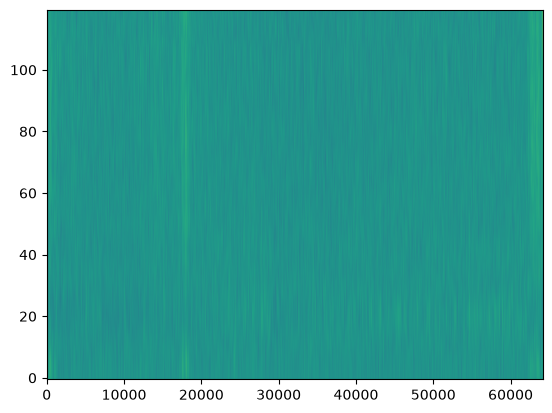

In [16]:
plt.figure()
plt.imshow(tfr[0],aspect='auto')
plt.gca().invert_yaxis()
plt.show()

# tensorboard + funcs

## old

In [ ]:
def elastic_net_loss(model, base_loss, l1_lambda=0, l2_lambda=0):
    l1_norm = base_loss.new_tensor(0.)
    l2_norm = base_loss.new_tensor(0.)
    for name, param in model.named_parameters():
        if not (param.requires_grad and 'weight' in name and 'bn' not in name.lower()):
            continue
        if l1_lambda:
            l1_norm += param.abs().sum()
        if l2_lambda:
            l2_norm += param.pow(2).sum()
    loss = base_loss
    if l1_lambda:
        loss = loss + l1_lambda * l1_norm
    if l2_lambda:
        loss = loss + l2_lambda * l2_norm
    return loss

In [ ]:
#launch tensorboard
from tensorboard import program
log_dir = "runs"
tb = program.TensorBoard()
tb.configure(argv=[None, '--logdir', log_dir])
tb_url = tb.launch()
print(f"TensorBoard is running at {tb_url}") #use ctrl+shift+p to find "simple browser"

In [ ]:
#depreciated
class EEGTransformerEncoderDecoder(nn.Module):
    """
    Transformer encoder/decoder for multi-channel EEG time series.

    Input:  (batch, C, N)   – C channels, N time steps per sample
    Output: (batch, C, N')  – C channels, N' output time steps (e.g. reconstruction or prediction)
    """

    def __init__(
        self,
        n_channels: int = 32,
        d_model: int = 128,
        nhead: int = 8,
        num_encoder_layers: int = 4,
        num_decoder_layers: int = 4,
        dim_feedforward: int = 256,
        dropout: float = 0.1,
        max_seq_len: int = 512,
        n_output_steps: int | None = None,  # if None, output length == input length
    ):
        super().__init__()
        self.spatial_attn = SpatialAttention(n_channels, d_k=16)
        self.local_conv = LocalTemporalConv(n_channels, kernel_size=5, stride=2)
        self.n_channels = n_channels
        self.d_model = d_model
        self.n_output_steps = n_output_steps or max_seq_len

        # Project C-channel signal at each time step into d_model
        self.input_proj = nn.Linear(n_channels, d_model)
        self.output_proj = nn.Linear(d_model, n_channels)

        # Learnable positional encodings
        self.encoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)
        self.decoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)

        # Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_encoder_layers)

        # Decoder
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_decoder_layers)

        # Masking
        self._build_causal_mask(max_seq_len)

    def _build_causal_mask(self, T: int):
        # Causal mask for decoder: position i can only attend to positions <= i
        self.register_buffer(
            "causal_mask",
            ~torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C, N = x.shape
        assert C == self.n_channels, f"Expected {self.n_channels} channels, got {C}"

        x = x.permute(0, 2, 1)
        x = self.spatial_attn(x)
        x = x.permute(0, 2, 1)
        x = self.local_conv(x)
        x = x.permute(0, 2, 1)

        x = self.input_proj(x)
        N_enc = x.size(1)
        x = x + self.encoder_pos[:, :N_enc, :]
        memory = self.encoder(x)            # ← remove the duplicate call

        N_out = self.n_output_steps
        tgt = torch.zeros(B, N_out, self.d_model, device=x.device, dtype=x.dtype)
        tgt = tgt + self.decoder_pos[:, :N_out, :]

        causal = self.causal_mask[:N_out, :N_out]
        # memory mask must be (N_out, N_enc), not (N, N_out)
        mem_mask = ~torch.triu(torch.ones(N_out, N_enc, dtype=torch.bool), diagonal=1)
        dec_out = self.decoder(
            tgt,
            memory,
            tgt_mask=causal,
            memory_mask=mem_mask,
        )

        out = self.output_proj(dec_out)
        out = out.permute(0, 2, 1)
        return out

In [ ]:
class LazyNeuroData(Dataset):
    def __init__(self, path='processed_data.pt', scale=1, transform=None,device='cpu'):
        processed=torch.load(path)
        self.data=processed['data'].to(device)
        self.labels=processed['labels'].to(device)
        self.num_samples = len(self.labels)
        self.scale = scale
        self.transform = transform

    def __len__(self): return self.num_samples
    
    def __getitem__(self, idx):
        data = self.data[idx]*self.scale #use transform here if required
        label = self.labels[idx]
        return data, label

In [ ]:
 
def collate_fn(batch):
    """
    Pads the number of windows, not the channels/time dimensions.

    Returns:
        padded_windows: (B, max_windows, C, window_size)
        labels:         (B,)
        pad_mask:       (B, max_windows)
                        False = real window
                        True  = padded window
    """

    windows_list = [item[0] for item in batch]
    labels_raw = [item[1] for item in batch]

    seq_lens = [w.shape[0] for w in windows_list]
    max_seq_len = max(seq_lens)

    padded_windows = []
    pad_masks = []

    for windows in windows_list:
        seq_len = windows.shape[0]
        pad_len = max_seq_len - seq_len

        # windows: (seq_len, channels, window_size)
        #
        # Pad only dimension 0 (number of windows).
        padded_wins = nn.functional.pad(
            windows,
            (0, 0,       # window_size
             0, 0,       # channels
             0, pad_len), # number of windows
            value=0.0
        )

        padded_windows.append(padded_wins)

        pad_masks.append(
            torch.cat([
                torch.zeros(seq_len, dtype=torch.bool),
                torch.ones(pad_len, dtype=torch.bool)
            ])
        )

    labels = torch.stack([
        torch.as_tensor(label)#, dtype=torch.long)
        for label in labels_raw
    ])

    return (
        torch.stack(padded_windows),
        labels,
        torch.stack(pad_masks)
    )


## new

In [17]:
def _load(paths, mmap=True):
    # mmap=True avoids loading all 20 subjects' TFRs into RAM (torch>=2.1)
    return [torch.load(p, mmap=mmap) for p in paths]

class RandomSliceDataset(Dataset):
    """Random windows from raw/TFR for autoencoder training.
    `win` is in TFR frames; the raw window is win*decim samples, aligned to the TFR."""

    def __init__(self, paths, win=256, decim=4, n_samples=10_000, mmap=True):
        self.sessions = _load(paths, mmap)
        self.win, self.decim, self.n_samples = win, decim, n_samples
        # usable length in TFR frames (guard against off-by-one from decimation)
        lengths = [min(s['tfr'].shape[-1], s['raw'].shape[-1] // decim)
                   for s in self.sessions]
        self.n_starts = [L - win + 1 for L in lengths]
        # sample recordings proportionally to how many windows they offer
        self.w = torch.tensor(self.n_starts, dtype=torch.float)

    def __len__(self):
        return self.n_samples  # "virtual epoch"; idx is ignored

    def __getitem__(self, idx):
        k = torch.multinomial(self.w, 1).item()
        t0 = torch.randint(0, self.n_starts[k], (1,)).item()   # TFR frame
        r0 = t0 * self.decim                                   # raw sample
        s = self.sessions[k]
        return {
            'raw': s['raw'][:, r0:r0 + self.win * self.decim].float(),
            'tfr': s['tfr'][..., t0:t0 + self.win].float(),
        }

class VarLenSliceDataset(Dataset):
    """Index is the window length (TFR frames); every item in a batch gets the same one."""
    def __init__(self, paths, decim=4, mmap=True):
        self.sessions = [torch.load(p, mmap=mmap) for p in paths]
        self.decim = decim
        self.lengths = [min(s['tfr'].shape[-1], s['raw'].shape[-1] // decim)
                        for s in self.sessions]

    def __len__(self):
        return 10**9  # irrelevant; the batch sampler controls iteration

    def __getitem__(self, win):
        w = torch.tensor([max(L - win + 1, 0) for L in self.lengths], dtype=torch.float)
        k = torch.multinomial(w, 1).item()
        t0 = torch.randint(0, int(w[k]), (1,)).item()
        r0 = t0 * self.decim
        s = self.sessions[k]
        return (s['raw'][:, r0:r0 + win * self.decim].float(),
                s['tfr'][..., t0:t0 + win].float())

class VarLenBatchSampler(Sampler):
    def __init__(self, n_batches, batch_size, min_win=64, max_win=1024, step=16):
        self.n_batches, self.bs = n_batches, batch_size
        self.min_win, self.max_win, self.step = min_win, max_win, step

    def __len__(self):
        return self.n_batches

    def __iter__(self):
        lo, hi = math.log(self.min_win), math.log(self.max_win)
        for _ in range(self.n_batches):
            win = int(round(math.exp(random.uniform(lo, hi)) / self.step)) * self.step
            yield [win] * self.bs   # the "indices" are the window length

class EventDataset(Dataset):
    """One item per n-back event. Window = [event - pre, event + post) in TFR frames.
    post=0 gives a strictly causal window ending at the event."""

    def __init__(self, paths, pre=256, post=0, decim=4, use_raw=False, mmap=True):
        self.sessions = _load(paths, mmap)
        self.pre, self.post, self.decim, self.use_raw = pre, post, decim, use_raw
        self.index = []  # (session_idx, start_frame, label)
        for k, s in enumerate(self.sessions):
            T = min(s['tfr'].shape[-1], s['raw'].shape[-1] // decim)
            for samp, lab in s['labels'].tolist():
                c = samp // decim
                a, b = c - pre, c + post
                if a >= 0 and b <= T:          # drop events too close to the edges
                    self.index.append((k, a, lab))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        k, a, lab = self.index[i]
        n = self.pre + self.post
        s = self.sessions[k]
        out = {'tfr': s['tfr'][..., a:a + n].float(),
               'label': torch.tensor(lab, dtype=torch.long)}
        if self.use_raw:
            out['raw'] = s['raw'][:, a * self.decim:(a + n) * self.decim].float()
        return out

torch.Size([4, 20, 1024]) torch.Size([4, 20, 120, 256])


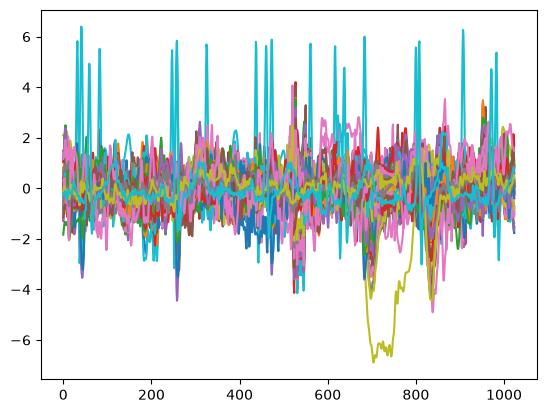

In [21]:
paths=['data/'+_d for _d in os.listdir('data')]
train = RandomSliceDataset(paths) #uses fixed length windows
trainloader= DataLoader(train,batch_size=4, shuffle=True)
data=next(iter(trainloader))
print(data['raw'].shape, data['tfr'].shape)

plt.figure()
for raw in data['raw']:
    plt.plot(raw.T)
plt.show()

torch.Size([4, 19, 384]) torch.Size([4, 19, 120, 96])


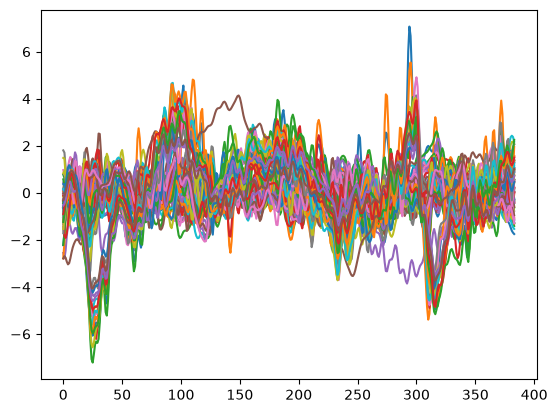

In [23]:
eeg_train=VarLenSliceDataset(paths)
for s in eeg_train.sessions:
    s['raw']=s['raw'][:-1]
    s['tfr']=s['tfr'][:-1]

trainloader= DataLoader(eeg_train,
                batch_sampler=VarLenBatchSampler(n_batches=2000, batch_size=4),
                num_workers=0)
data=next(iter(trainloader))
raw=data[0]
tfr=data[1]
print(raw.shape, tfr.shape)

plt.figure()
for r in raw:
    plt.plot(r.T)
plt.show()

In [47]:
class SpatialAttention(nn.Module):
    """Per-timestep attention across electrodes."""
    def __init__(self, n_channels, d_k=16, dropout=0.1):
        super().__init__()
        self.q = nn.Linear(1, d_k)
        self.k = nn.Linear(1, d_k)
        self.ch_q = nn.Parameter(torch.randn(n_channels, d_k) * 0.02)
        self.ch_k = nn.Parameter(torch.randn(n_channels, d_k) * 0.02)
        self.drop = nn.Dropout(dropout)
        self.scale = d_k ** -0.5

    def forward(self, x):                      # x: (B, N, C)
        v = x.unsqueeze(-1)                    # (B, N, C, 1)
        q = self.q(v) + self.ch_q              # (B, N, C, d_k)
        k = self.k(v) + self.ch_k
        attn = (q @ k.transpose(-1, -2)) * self.scale   # (B, N, C, C)
        attn = self.drop(attn.softmax(-1))
        return x + (attn @ v).squeeze(-1)      # residual, (B, N, C)
    
def sinusoidal_pos(T, d, device):
    pos = torch.arange(T, device=device).unsqueeze(1)
    div = torch.exp(torch.arange(0, d, 2, device=device) * (-math.log(10000.0) / d))
    pe = torch.zeros(T, d, device=device)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

class RawToTFR(nn.Module):
    def __init__(self, n_channels=20, n_freqs=120, d_model=128, nhead=8,
                 num_layers=4, dim_ff=256, dropout=0.1, use_spatial_attn=False):
        super().__init__()
        self.C, self.F = n_channels, n_freqs
        self.spatial = SpatialAttention(n_channels) if use_spatial_attn else None
        # 4x temporal downsampling (decim=4), channels -> d_model
        self.stem = nn.Sequential(
            nn.Conv1d(n_channels, d_model, kernel_size=7, stride=2, padding=3),
            nn.GELU(),
            nn.Conv1d(d_model, d_model, kernel_size=7, stride=2, padding=3),
        )
        self.norm_in = nn.LayerNorm(d_model)
        layer = nn.TransformerEncoderLayer(d_model, nhead, dim_ff, dropout,
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(
            layer, num_layers,
            enable_nested_tensor=False,
            norm=nn.LayerNorm(d_model),   # see below
        )
        self.head = nn.Linear(d_model, n_channels * n_freqs)

    def forward(self, x):                          # x: (B, C, 4T)
        if self.spatial is not None:
            x = self.spatial(x.transpose(1, 2)).transpose(1, 2)
        z = self.stem(x).transpose(1, 2)           # (B, T, d_model)
        z = self.norm_in(z)
        z = z + sinusoidal_pos(z.size(1), z.size(2), z.device)
        z = self.encoder(z)                        # (B, T, d_model)
        out = self.head(z)                         # (B, T, C*F)
        B, T, _ = out.shape
        return out.view(B, T, self.C, self.F).permute(0, 2, 3, 1)  # (B, C, F, T)

In [ ]:
#updated ver
# ─────────────────────────────────────────────────────────────
#  Head  –  small MLP with residual skip
# ─────────────────────────────────────────────────────────────
class Head(nn.Module):
    """
    (B, T', d_model) → (B, T', C * F)
    Two hidden layers + GELU, LayerNorm, and a linear residual skip
    so the MLP only has to learn the *correction*.
    """
    def __init__(self, d_model: int, out_dim: int, hidden: int | None = None,
                 dropout: float = 0.1):
        super().__init__()
        h = hidden or 2 * d_model
        self.norm = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, h),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h, h),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.proj = nn.Linear(h, out_dim)
        self.skip = nn.Linear(d_model, out_dim)   # residual linear

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.mlp(self.norm(x))
        return self.proj(h) + self.skip(self.norm(x))


# ─────────────────────────────────────────────────────────────
#  Full model
# ─────────────────────────────────────────────────────────────
class RawToTFR(nn.Module):
    """
    EEG  (B, C, T_raw)  →  TFR  (B, C, F, T_raw // decim)

    decim = 4  with the default stem (two stride-2 convs).
    """
    def __init__(
        self,
        n_channels: int = 20,
        n_freqs: int = 120,
        d_model: int = 128,
        nhead: int = 8,
        num_layers: int = 4,
        dim_ff: int = 512,
        dropout: float = 0.1,
        decim: int = 4,          # 2 or 4; must match the stem
        use_spatial_attn: bool = True,
    ):
        super().__init__()
        self.C, self.F = n_channels, n_freqs
        self.decim = decim

        # ── optional raw-signal spatial mixer ──
        self.spatial_raw = (
            SpatialAttention(n_channels, d_k=32) if use_spatial_attn else None
        )

        # ── stem:  T_raw → T_raw // decim,  C → d_model ──
        if decim == 4:
            self.stem = nn.Sequential(
                nn.Conv1d(n_channels, d_model, kernel_size=7, stride=2, padding=3),
                nn.GELU(),
                nn.Conv1d(d_model, d_model, kernel_size=7, stride=2, padding=3),
                nn.GELU(),
            )
        elif decim == 2:
            self.stem = nn.Sequential(
                nn.Conv1d(n_channels, d_model, kernel_size=7, stride=2, padding=3),
                nn.GELU(),
            )
        else:
            raise ValueError(f"decim must be 2 or 4, got {decim}")

        # ── channel identity embedding (learnable) ──
        self.ch_emb = nn.Parameter(
            0.02 * torch.randn(n_channels, d_model)
        )
        # We'll add ch_emb[c] to the feature of channel c via a small
        # 1-D conv trick after the stem (see _add_channel_info below).

        self.norm_in = nn.LayerNorm(d_model)

        # ── transformer ──
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            norm_first=True,          # Pre-LN: more stable for deep stacks
        )
        self.encoder = nn.TransformerEncoder(
            enc_layer,
            num_layers=num_layers,
            enable_nested_tensor=False,   # ← important for variable T
            norm=nn.LayerNorm(d_model),
        )

        # ── head ──
        self.head = Head(
            d_model=d_model,
            out_dim=n_channels * n_freqs,
            hidden=2 * d_model,
            dropout=dropout,
        )

        self._init_weights()

    # ── helpers ──────────────────────────────────────────────
    def _add_channel_info(self, z: torch.Tensor) -> torch.Tensor:
        """
        z: (B, T', d_model)  –  the transformer sees *time* tokens.
        We inject a channel-aware bias by running a 1-D conv over the
        channel axis *before* the stem, so d_model already carries
        channel identity.  Here we simply add a learned per-channel
        offset that was mixed in by the stem's first conv.
        (If you want an explicit additive channel code, swap the stem
         for a Conv2d(C, F, 1, 1) on a reshaped input.)
        """
        # Lightweight version: add the channel-mean of ch_emb as a global bias
        # (the per-channel structure is already in the stem's C → d_model conv).
        return z + self.ch_emb.mean(0).unsqueeze(0).unsqueeze(0)  # (1, 1, d)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    # ── forward ──────────────────────────────────────────────
    def forward(
        self,
        x: torch.Tensor,                       # (B, C, T_raw)
        padding_mask: torch.Tensor | None = None,  # (B, T_raw)  True = pad
    ) -> torch.Tensor:                         # (B, C, F, T')
        B, C, T_raw = x.shape

        # 1 – optional raw spatial mixer
        if self.spatial_raw is not None:
            x = self.spatial_raw(x.transpose(1, 2)).transpose(1, 2)

        # 2 – stem  (T_raw → T')
        z = self.stem(x)                       # (B, d_model, T')
        z = z.transpose(1, 2)                  # (B, T', d_model)
        z = self.norm_in(z)

        # 3 – positional + channel info
        z = z + sinusoidal_pos(z.size(1), z.size(2), z.device)
        z = z + self._add_channel_info(z)

        # 4 – build the (post-stem) padding mask if needed
        src_mask = None
        if padding_mask is not None:
            # Downsample the mask by the same factor as the stem.
            # Simple approach: take the *first* element of each decim-chunk.
            T_raw_mask = padding_mask.shape[1]
            T_stem = z.size(1)
            indices = (torch.arange(T_stem, device=x.device) * self.decim)
            indices = indices.clamp(max=T_raw_mask - 1)
            src_mask = padding_mask[:, indices]   # (B, T')  True = pad

        # 5 – transformer
        z = self.encoder(z, src_key_padding_mask=src_mask)  # (B, T', d_model)

        # 6 – head + reshape
        out = self.head(z)                             # (B, T', C*F)
        B, T_out, _ = out.shape
        out = out.view(B, T_out, self.C, self.F)
        return out.permute(0, 2, 3, 1)                # (B, C, F, T')


In [52]:
paths=['data/'+_d for _d in os.listdir('data')]
eeg_train=VarLenSliceDataset(paths)
for s in eeg_train.sessions: #remove ecg channels for now
    s['raw']=s['raw'][:-1]
    s['tfr']=s['tfr'][:-1]

trainloader= DataLoader(eeg_train,
                batch_sampler=VarLenBatchSampler(n_batches=2000, batch_size=64),
                num_workers=0)

device='cuda' if torch.cuda.is_available() else 'cpu'
tfr_encoder=RawToTFR(n_channels=19,use_spatial_attn=True,d_model=128*2).to(device)
#optimizer = torch.optim.Adam(tfr_encoder.parameters(), lr=1e-6)
#schedular=torch.optim.lr_scheduler.StepLR(optimizer, gamma=0.1,step_size=100)

# Optimiser – AdamW with a small weight decay on the head
params = [
    {"params": [p for n, p in tfr_encoder.named_parameters()
                if "head" not in n and "spatial" not in n],
     "weight_decay": 0.01},
    {"params": [p for n, p in tfr_encoder.named_parameters()
                if "head" in n or "spatial" in n],
     "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(params, lr=3e-4, betas=(0.9, 0.95))

# Training loop
losses=[]
lr=[]
tfr_encoder.train()
nepochs=3
for epoch in range(nepochs):
    print(f"Epoch {epoch+1}/{nepochs}")
    for batch in trainloader:
        #forward
        raw=batch[0].to(device)
        tfr=batch[1].to(device)
        optimizer.zero_grad()
        output = tfr_encoder(raw)

        #backward
        loss = F.mse_loss(output, tfr)
        loss.backward()
        optimizer.step()

        losses.append(loss.cpu().item())

        #schedualing
        #schedular.step()
        #lr.append(schedular.get_last_lr())

Epoch 1/3
Epoch 2/3
Epoch 3/3


In [ ]:
# Optimiser – AdamW with a small weight decay on the head
params = [
    {"params": [p for n, p in model.named_parameters()
                if "head" not in n and "spatial" not in n],
     "weight_decay": 0.01},
    {"params": [p for n, p in model.named_parameters()
                if "head" in n or "spatial" in n],
     "weight_decay": 0.0},
]
opt = torch.optim.AdamW(params, lr=3e-4, betas=(0.9, 0.95))
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=200_000)

# Loss – MSE in the TFR plane is fine to start; if the TFR is complex,
# use  MSE(real) + MSE(imag)  or  |pred - target|_2^2.
criterion = nn.MSELoss()

# Warm-up helps a lot with the transformer layers
warmup_steps = 10_000
def lr_lambda(step):
    if step < warmup_steps:
        return step / warmup_steps
    return sched.get_last_lr()[0] / 3e-4   # or just use Cosine directly


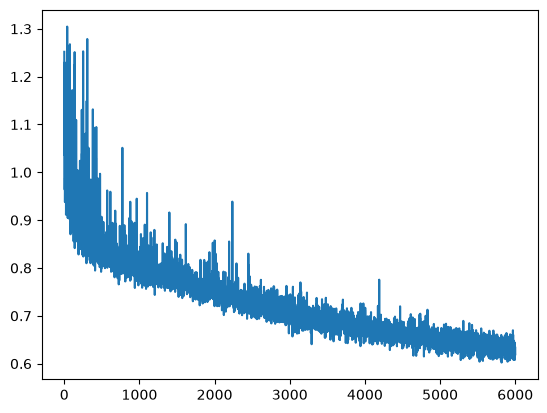

In [53]:
plt.plot(losses)

In [54]:
tfr_encoder.eval()
with torch.no_grad():
    batch=next(iter(trainloader))
    raw=batch[0].to(device)
    tfr=batch[1].to(device)
    output=tfr_encoder(raw)

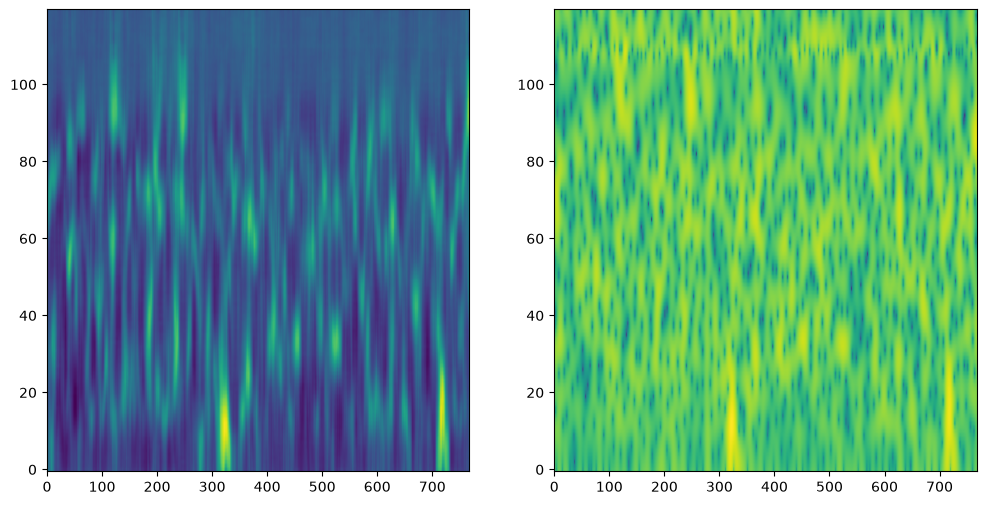

In [55]:
channel=-1
fig, axs=plt.subplots(1,2,figsize=[12,6])
axs[0].imshow(output[0,channel].cpu(),aspect='auto')
axs[0].invert_yaxis()
axs[1].imshow(tfr[0,channel].cpu(),aspect='auto')
axs[1].invert_yaxis()
plt.show()

## autoencoder

In [14]:
class SpatialAttention(nn.Module):
    """Channel-mixing via learned attention over C electrodes at each time step."""
    def __init__(self, n_channels: int, d_k: int = 16, dropout: float = 0.1):
        super().__init__()
        self.q = nn.Linear(n_channels, d_k)
        self.k = nn.Linear(n_channels, d_k)
        self.v = nn.Linear(n_channels, n_channels)
        self.attn_drop = nn.Dropout(dropout)
        self.scale = d_k ** -0.5

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, N, C)
        q = self.q(x)#.permute(0, 2, 1)   # (B, C, N)
        k = self.k(x).permute(0,2,1)                    # (B, N, C)
        attn = torch.bmm(q, k) * self.scale  # (B, C, C)
        attn = F.softmax(attn, dim=-1)
        attn = self.attn_drop(attn)
        out = torch.bmm(attn.permute(0, 2, 1), x)
        return out

class LocalTemporalConv(nn.Module):
    """Short 1-D conv to extract local temporal patterns and shorten sequence."""
    def __init__(self, n_channels: int, kernel_size: int = 5, stride: int = 2):
        super().__init__()
        pad = (kernel_size - 1) // 2
        self.conv = nn.Conv1d(n_channels, n_channels, kernel_size, stride=stride, padding=pad)
        self.norm = nn.LayerNorm(n_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, C, N)
        x = self.conv(x)
        x = self.norm(x.transpose(1, 2)).transpose(1, 2)
        return x

In [3]:
class EEGEncoder(nn.Module):
    """Extracts a latent representation from the EEG signal."""
    def __init__(
        self,
        n_channels: int = 32,
        d_model: int = 128,
        nhead: int = 8,
        num_encoder_layers: int = 4,
        dim_feedforward: int = 256,
        dropout: float = 0.1,
        max_seq_len: int = 512,
    ):
        super().__init__()
        self.spatial_attn = SpatialAttention(n_channels, d_k=16)
        self.local_conv = LocalTemporalConv(n_channels, kernel_size=5, stride=2)
        
        self.input_proj = nn.Linear(n_channels, d_model)
        
        # Learnable positional encodings
        self.encoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_encoder_layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, C, N)
        B, C, N = x.shape
        
        # Pre-processing
        x = x.permute(0, 2, 1)           # (B, N, C)
        x = self.spatial_attn(x)        # (B, N, C)
        x = x.permute(0, 2, 1)           # (B, C, N)
        x = self.local_conv(x)          # (B, C, N')
        x = x.permute(0, 2, 1)           # (B, N', C)

        # Projection and Encoding
        x = self.input_proj(x)          # (B, N', d_model)
        x = x + self.encoder_pos[:, :x.size(1), :]
        
        latent = self.transformer_encoder(x)
        return latent  # This is your latent representation

class EEGDecoder(nn.Module):
    """Reconstructs the original signal from the latent representation."""
    def __init__(
        self,
        n_channels: int = 32,
        d_model: int = 128,
        nhead: int = 8,
        num_decoder_layers: int = 4,
        dim_feedforward: int = 256,
        dropout: float = 0.1,
        max_seq_len: int = 512,
        n_output_steps: int = None,
    ):
        super().__init__()
        self.n_output_steps = n_output_steps or max_seq_len
        
        self.decoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)
        
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.transformer_decoder = nn.TransformerDecoder(decoder_layer, num_decoder_layers)
        self.output_proj = nn.Linear(d_model, n_channels)
        
        # Causal mask
        self.register_buffer(
            "causal_mask",
            ~torch.triu(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool), diagonal=1),
        )

    def forward(self, memory: torch.Tensor, tgt_len: int) -> torch.Tensor:
        B, N_enc, D = memory.shape
        
        # Create a dummy target sequence (or use a shifted version of the input)
        # For a pure autoencoder, we often use a zero-initialized or shifted sequence
        tgt = torch.zeros(B, tgt_len, memory.size(-1), device=memory.device, dtype=memory.dtype)
        tgt = tgt + self.decoder_pos[:, :tgt_len, :]

        causal = self.causal_mask[:tgt_len, :tgt_len]
        mem_mask = ~torch.triu(torch.ones(tgt_len, N_enc, dtype=torch.bool, device=memory.device,), diagonal=1)
        
        dec_out = self.transformer_decoder(
            tgt,
            memory,
            tgt_mask=causal,
            memory_mask=mem_mask,
        )
        
        out = self.output_proj(dec_out)
        return out.permute(0, 2, 1) # (B, C, N)

class EEGAutoencoder(nn.Module):
    """Combined model for training."""
    def __init__(self, **kwargs):
        super().__init__()
        self.encoder = EEGEncoder(**kwargs)
        self.decoder = EEGDecoder(**kwargs)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        latent = self.encoder(x)
        # The decoder attempts to reconstruct the shape of the input
        # Note: You may need to adjust logic if the local_conv changes N
        reconstruction = self.decoder(latent, x.shape[2])
        return reconstruction

In [12]:
nsamples=100
nchannels=32
nfeatures=256

x=torch.randint(low=nfeatures*3,
                high=nfeatures*10,
                size=[nsamples])

frequencies = torch.randint(1,100,size=[nsamples]) #[f for f in range(1, 6)] # or any other logic to match len(x)

# Use zip to iterate over both lengths and frequencies
signals = [
    torch.stack([
        torch.sin(torch.linspace(0, 2 * torch.pi * f, steps=L))
        + torch.randn(L)
        for ch in range(nchannels)
    ])
    for L, f in zip(x, frequencies)
]
signals = nn.utils.rnn.pad_sequence(
    [s.T for s in signals],
    batch_first=True
).permute(0,2,1)
dataset=torch.utils.data.TensorDataset(signals,frequencies)
dataloader=DataLoader(dataset, batch_size=10,shuffle=True)

In [17]:
# Set seed for reproducibility
torch.manual_seed(42)

# Parameters (matching your existing setup)
nsamples = 100
nchannels = 32
nfeatures = 256  # This determines the sequence length L

# 1. Generate variable lengths L and a set of "signature" frequencies
# Each sample will have 3 primary frequencies that define its "identity"
x = torch.randint(low=nfeatures*3, high=nfeatures*10, size=[nsamples])
# Each sample gets 3 unique base frequencies
base_freqs = torch.randint(low=1, high=100, size=[nsamples, 3])

# 2. Generate the signals
signals = []
for i in range(nsamples):
    L = x[i].item()
    # Get the 3 base frequencies for this sample
    freqs = base_freqs[i]
    
    # Create a mixture of 3 sine waves with random phases and amplitudes
    # This ensures the model has to learn to reconstruct a specific "harmonic profile"
    sample_signal = torch.zeros((nchannels, L))
    for ch in range(nchannels):
        # Each channel has a slightly different phase to simulate real-world variance
        phase = torch.rand(1) * 2 * torch.pi
        
        # Sum of 3 sines
        sig = (
            1.0 * torch.sin(2 * torch.pi * freqs[0] * torch.arange(L) / L + phase) +
            0.7 * torch.sin(2 * torch.pi * freqs[1] * torch.arange(L) / L + phase) +
            0.4 * torch.sin(2 * torch.pi * freqs[2] * torch.arange(L) / L + phase)
        )
        # Add some Gaussian noise
        sig += torch.randn(L) * 0.1 
        sample_signal[ch] = sig
    
    signals.append(sample_signal)

# 3. Pad and format for the model
# We use the same logic as your original code to ensure compatibility
signals = nn.utils.rnn.pad_sequence(
    [s.T for s in signals],
    batch_first=True
).permute(0, 2, 1)

# The frequencies are used as a "ground truth" for validation of the signal profile
dataset = TensorDataset(signals, base_freqs)
dataloader = DataLoader(dataset, batch_size=10, shuffle=True)

print(f"Dataset created. Shape: {signals.shape}") # Should be [100, 32, nfeatures*10]

Dataset created. Shape: torch.Size([100, 32, 2532])


In [19]:
#autoencoder training
device='cuda' if torch.cuda.is_available() else 'cpu'
autoencoder = EEGAutoencoder(n_channels=32, d_model=128,max_seq_len=signals.shape[-1]).to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-4)
schedular=torch.optim.lr_scheduler.StepLR(optimizer, gamma=0.1,step_size=100)

# Training loop
losses=[]
lr=[]
autoencoder.train()
for epoch in range(100):
    for batch in dataloader:
        x=batch[0].to(device)
        y=batch[1].to(device)
        optimizer.zero_grad()
        output = autoencoder(x)
        loss = F.mse_loss(output, x)
        loss.backward()
        optimizer.step()
        losses.append(loss.cpu().item())

        schedular.step()
        lr.append(schedular.get_last_lr())

plt.figure()
plt.plot(losses)
plt.show()

autoencoder.eval()
#with torch.no_grad():
x_pred=autoencoder(x)
plt.figure()
plt.plot(x[0,0].cpu())
plt.plot(x_pred[0,0].detach().cpu(),linestyle='--',color='red')
plt.show()

# Load only the encoder
#encoder = EEGEncoder(n_channels=32, d_model=128)
#encoder.load_state_dict(torch.load('encoder_weights.pt'))
#encoder.eval()

#with torch.no_grad():
#    latent_representation = encoder(input_data)
    # Proceed with predictions using latent_representation

[W1031 00:46:11.367300632 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 257949696 bytes (free: 5242880, total: 3951624192).
[W1031 00:46:13.900649112 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 257949696 bytes (free: 156237824, total: 3951624192).
[W1031 00:46:13.900729763 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 257949696 bytes (free: 156237824, total: 3951624192).


OutOfMemoryError: CUDA out of memory. Tried to allocate 246.00 MiB. GPU 0 has a total capacity of 3.68 GiB of which 149.00 MiB is free. Including non-PyTorch memory, this process has 3.52 GiB memory in use. Of the allocated memory 2.29 GiB is allocated by PyTorch, and 1.11 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [11]:

print(f"Parameters: {sum(p.numel() for p in autoencoder.parameters()):,}")


Parameters: 1,993,792


In [5]:
# ── Instantiate model ──
model = EEGTransformerEncoderDecoder(
    n_channels=32,
    d_model=128,
    nhead=8,
    num_encoder_layers=4,
    num_decoder_layers=4,
    dim_feedforward=256,
    dropout=0.1,
    max_seq_len=512,
    n_output_steps=128,       # predict next 128 steps
)
model.eval()
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


Parameters: 1,471,808


In [6]:
# ── Test 1: basic forward pass ──
x = torch.randn(4, 32, 256)   # batch=4, C=32, N=256
with torch.no_grad():
    y = model(x)
print(f"\nTest 1 – forward pass")
print(f"  Input:  {tuple(x.shape)}")
print(f"  Output: {tuple(y.shape)}")
assert y.shape[0] == 4 and y.shape[1] == 32, "Shape mismatch!"

RuntimeError: Expected size for first two dimensions of batch2 tensor to be: [4, 16] but got: [4, 256].

In [ ]:
# ── Test 2: different sequence lengths ──
for N in [64, 128, 512]:
    x = torch.randn(2, 32, N)
    with torch.no_grad():
        y = model(x)
    print(f"Test 2 – N={N:3d}  →  output {tuple(y.shape)}")


In [ ]:
# ── Test 3: single sample ──
x1 = torch.randn(1, 32, 256)
with torch.no_grad():
    y1 = model(x1)
print(f"Test 3 – batch=1  →  output {tuple(y1.shape)}")


In [ ]:
# ── Test 4: gradient flow (training step) ──
model.train()
x = torch.randn(4, 32, 256, requires_grad=False)
y = model(x)
loss = F.mse_loss(y, x[:, :, :y.shape[2]])   # reconstruct first N_out samples
loss.backward()

# Check that gradients exist for key params
grads_ok = all(
    p.grad is not None and torch.isfinite(p.grad).all()
    for p in model.parameters() if p.requires_grad
)
print(f"\nTest 4 – backward pass")
print(f"  Loss:     {loss.item():.6f}")
print(f"  Grads:    {'OK (finite, non-None)' if grads_ok else 'FAILED'}")

# ── Test 5: numerical stability (extreme inputs) ──
x_big  = torch.randn(2, 32, 128) * 10    # large amplitude
x_small = torch.randn(2, 32, 128) * 0.01 # near-zero
with torch.no_grad():
    y_big  = model(x_big)
    y_small = model(x_small)
print(f"\nTest 5 – numerical stability")
print(f"  x*10    → finite: {torch.isfinite(y_big).all().item()}")
print(f"  x*0.01  → finite: {torch.isfinite(y_small).all().item()}")

print("\n✓ All tests passed")

Parameters: 1,471,808


RuntimeError: Expected size for first two dimensions of batch2 tensor to be: [4, 16] but got: [4, 256].